# Week 6: Statistical Validation & Predictive Maintenance

## Part A: Statistical Validation

This section evaluates whether equipment vibration differs significantly between day and night shifts using an independent two-sample t-test and a 95% confidence interval.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv("data/pdm_synthetic_features.csv")

df.head()

,timestamp,asset_id,depot,shift,asset_age_months,vibration_g,temperature_c,pressure_psi,acoustic_db,motor_current_a,error_events,constant_sensor,time_to_failure_hours,health_status,fault_type,failure_within_7_days,vibration_roll_mean_6,vibration_rms_6,vibration_peak_to_peak_6,temp_roll_mean_6
0,01/01/2026 00:00,PUMP-001,North,Day,15,1.3056,64.4815,123.4455,69.9614,34.8057,0,1,641.33,Healthy,Normal,0,1.305600,1.305600,0.0000,64.481500
1,01/01/2026 06:00,PUMP-001,North,Night,15,1.8329,65.2009,121.4905,70.8481,34.6576,1,1,658.44,Healthy,Normal,0,1.569250,1.591244,0.5273,64.841200
2,01/01/2026 12:00,PUMP-001,North,Day,15,1.7601,63.9732,123.0420,69.1901,36.7452,0,1,638.09,Healthy,Normal,0,1.632867,1.649451,0.5273,64.551867
3,01/01/2026 18:00,PUMP-001,North,Night,15,2.0155,63.6278,122.7399,68.1283,36.8624,0,1,644.73,Healthy,Normal,0,1.728525,1.748164,0.7099,64.320850
4,02/01/2026 00:00,PUMP-001,North,Day,15,1.3916,65.4224,127.2597,71.2493,35.0683,0,1,633.20,Healthy,Normal,0,1.661140,1.682906,0.7099,64.541160


In [3]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (2640, 20)

Columns:
['timestamp', 'asset_id', 'depot', 'shift', 'asset_age_months', 'vibration_g', 'temperature_c', 'pressure_psi', 'acoustic_db', 'motor_current_a', 'error_events', 'constant_sensor', 'time_to_failure_hours', 'health_status', 'fault_type', 'failure_within_7_days', 'vibration_roll_mean_6', 'vibration_rms_6', 'vibration_peak_to_peak_6', 'temp_roll_mean_6']

Data types:
timestamp                    object
asset_id                     object
depot                        object
shift                        object
asset_age_months              int64
vibration_g                 float64
temperature_c               float64
pressure_psi                float64
acoustic_db                 float64
motor_current_a             float64
error_events                  int64
constant_sensor               int64
time_to_failure_hours       float64
health_status                object
fault_type                   object
failure_within_7_days         int64
vibration_roll_mean_6

In [4]:
df[['shift', 'vibration_g']].head(10)

,shift,vibration_g
0,Day,1.3056
1,Night,1.8329
2,Day,1.7601
3,Night,2.0155
4,Day,1.3916
5,Day,1.6969
6,Night,1.5453
7,Night,1.6593
8,Day,1.3104
9,Night,1.7426


## 1.2 Exploring Vibration by Shift

Before conducting the hypothesis test, we compare the descriptive statistics and distributions of vibration readings for the day and night shifts.

In [5]:
df.groupby('shift')['vibration_g'].agg(
    ['count', 'mean', 'std', 'min', 'max']
)

,count,mean,std,min,max
shift,,,,,
Day,1467,2.167536,0.876595,0.6768,10.48078
Night,1173,2.260485,0.855860,0.7256,5.26020


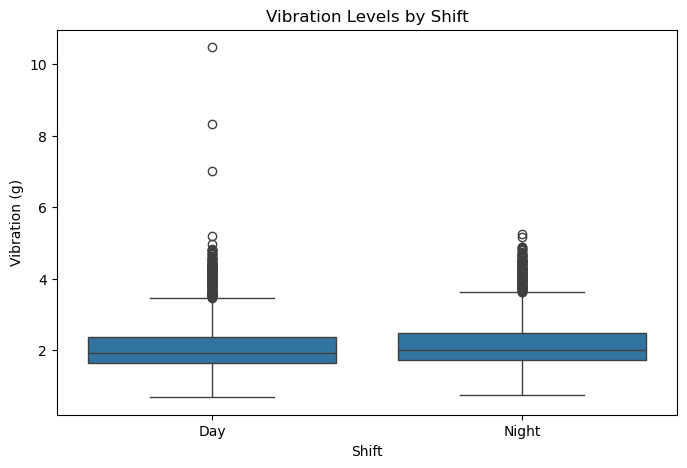

In [6]:
#Visual comparison
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='shift', y='vibration_g')

plt.title('Vibration Levels by Shift')
plt.xlabel('Shift')
plt.ylabel('Vibration (g)')

plt.show()

## 1.3 Hypothesis Formulation

Research Question:

Is there a statistically significant difference in average vibration levels between day and night shifts?

Null Hypothesis (H₀):

There is no statistically significant difference in mean vibration levels between the day and night shifts.

Alternative Hypothesis (H₁):

There is a statistically significant difference in mean vibration levels between the day and night shifts.

The significance level is set at α = 0.05.

## 1.4 Statistical Test Selection

An independent two-sample Welch's t-test will be used because the objective is to compare the mean vibration levels of two independent groups: day-shift and night-shift observations.

Welch's t-test is appropriate because it does not require the two groups to have equal variances.

A significance level of 0.05 will be used.

In [7]:
day_vibration = df.loc[
    df['shift'] == 'Day',
    'vibration_g'
].dropna()

night_vibration = df.loc[
    df['shift'] == 'Night',
    'vibration_g'
].dropna()

In [8]:
print("Day observations:", len(day_vibration))
print("Night observations:", len(night_vibration))

Day observations: 1467
Night observations: 1173


In [9]:
t_stat, p_value = stats.ttest_ind(
    day_vibration,
    night_vibration,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -2.742983360247718
P-value: 0.006131178612168355


## 1.6 Statistical Test Interpretation

The Welch's independent two-sample t-test produced a t-statistic of approximately -2.743 and a p-value of approximately 0.0061.

Because the p-value is less than the significance level of 0.05, we reject the null hypothesis.

This provides statistically significant evidence that mean vibration levels differ between the day and night shifts.

The descriptive statistics show that the night shift has a higher average vibration level than the day shift.

In [10]:
day_mean = day_vibration.mean()
night_mean = night_vibration.mean()

mean_difference = day_mean - night_mean

print("Day mean:", day_mean)
print("Night mean:", night_mean)
print("Mean difference:", mean_difference)

Day mean: 2.167535760054533
Night mean: 2.260484722932651
Mean difference: -0.09294896287811794


In [11]:
#Welch 95% Confidence Interval
n_day = len(day_vibration)
n_night = len(night_vibration)

day_std = day_vibration.std(ddof=1)
night_std = night_vibration.std(ddof=1)

standard_error = np.sqrt(
    (day_std**2 / n_day) +
    (night_std**2 / n_night)
)

degrees_of_freedom = (
    ((day_std**2 / n_day) + (night_std**2 / n_night))**2
    /
    (
        ((day_std**2 / n_day)**2 / (n_day - 1))
        +
        ((night_std**2 / n_night)**2 / (n_night - 1))
    )
)

t_critical = stats.t.ppf(
    0.975,
    degrees_of_freedom
)

margin_of_error = t_critical * standard_error

ci_lower = mean_difference - margin_of_error
ci_upper = mean_difference + margin_of_error

print("95% Confidence Interval:")
print("Lower:", ci_lower)
print("Upper:", ci_upper)

95% Confidence Interval:
Lower: -0.15939617677163037
Upper: -0.026501748984605514


## 1.8 Confidence Interval Interpretation

The estimated difference in mean vibration between the day and night shifts is approximately -0.093 g, where the difference is calculated as Day minus Night.

The 95% confidence interval for this difference is approximately -0.159 g to -0.027 g.

Because the confidence interval does not contain zero, it supports the conclusion that there is a statistically significant difference in mean vibration between the two shifts.

Since the interval is entirely negative, the results indicate that average vibration is higher during the night shift than during the day shift.